In [1]:
import numpy as np
from scipy import special
from numba import njit, prange
import math
import matplotlib.pyplot as plt

## 1. Introducción y objetivo

Queremos evaluar numéricamente la cantidad

$$
G^{\mathrm{bulk}}(t)
=
\int_V \int_V
\frac{Y_2^0(r)}{r^3}\,\frac{Y_2^0(r_0)}{r_0^3}\,
P(r,t\mid r_0)\; d^3r\, d^3r_0,
$$

donde:

- $P(r,t\mid r_0)$ es el propagador de difusión en un cilindro con condiciones de Dirichlet en $\rho=R$ y en $z=d,\,d+L$.
- $Y_2^0$ es el armónico esférico de orden 2, proyección 0.
- La integración es sobre volúmenes $d^3r = \rho\, d\rho\, d\phi\, dz$ en coordenadas cilíndricas.

**Estrategia:** usar la expansión modal del propagador en funciones separables en $\phi$, $\rho$ y $z$, explotar la simetría angular para fijar $n=0$, y reducir la integral cuádruple a una suma modal donde cada término es producto de dos integrales dobles (una sobre $(\rho,z)$ y otra sobre $(\rho_0,z_0)$). Estas integrales dobles son las que evaluamos numéricamente con cuadratura Gauss–Legendre y luego sumamos sobre modos con Numba para eficiencia.

## 2. Zeros de Bessel y modos radiales

**Objetivo matemático:** encontrar los estilos radiales que satisfacen $J_n(\beta R)=0$ con $n=0$ (debido a la simetría en $\phi$). Para $n=0$ denotamos los ceros por $\alpha_{0,p}$ ($p=1,2,\dots$). Entonces

$$
\beta_p = \frac{\alpha_{0,p}}{R} \quad\text{(unidades: $1/\text{longitud}$)}.
$$

Estos $\beta_p$ aparecen en los autovalores del Laplaciano radial y en los modos $J_0(\beta_p \rho)$ que forman una base ortogonal en $[0,R]$ con peso $\rho$. En la práctica numérica:

- `zeros_J0(p_max)` obtiene los primeros $p_{\max}$ ceros $\alpha_{0,p}$ de $J_0$ (función de Bessel de primera especie).
- Usamos $\beta_p = \alpha_{0,p}/R$ para trabajar en la unidad inversa de longitud (ej. $1/\text{nm}$ si $R$ está en nm).

**Por qué es necesario:** los ceros determinan la discretización física del espacio radial impuesta por la condición de Dirichlet en $\rho=R$; sin ellos la expansión modal sería incorrecta para la frontera.

In [2]:
# ------------------ Parámetros y utilidades (unidades: nm, µs) ------------------
def zeros_J0(p_max):
    return special.jn_zeros(0, p_max)  # zeros of J0 (array length p_max)

## 3. Kernel físico $W(\rho,z)$

La función que integraremos contra los modos radiales/axiales contiene el factor angular y la dependencia radial/axial del armónico esférico:

Partimos de

$$
\frac{Y_2^0(r)}{r^3} \quad\text{en coordenadas cilíndricas, con } r^2=\rho^2+z^2.
$$

Esto lleva a definir el kernel (incluyendo el factor $\rho$ del jacobiano):

$$
W(\rho,z) \equiv \rho\left[\frac{3z^2}{(\rho^2+z^2)^{5/2}} - \frac{1}{(\rho^2+z^2)^{3/2}}\right].
$$

Notas numéricas:

- Para puntos muy cercanos a $(\rho,z)=(0,0)$ la expresión puede ser sensible; en la implementación se evita división por cero (reemplazando denominadores nulos por $\infty$).
- `W_rz_vec` está vectorizada: acepta arrays `rho` y `z` con broadcasting y devuelve una matriz $W_{ij}=W(\rho_i,z_j)$.

**Por qué es necesario:** esta función es la que contiene la física del acoplamiento dipolar ($Y_2^0/r^3$). Multiplicada por $J_0(\beta_p \rho)$ y por la función axial (seno/coseno) da las integrandas modales que se integran en $\rho$ y $z$.

In [3]:
def W_rz_vec(rho, z):
    # rho, z can be numpy arrays (same shape broadcasting)
    denom = rho*rho + z*z
    # avoid divide by zero (set denom->inf) if necessary
    denom = np.where(denom == 0.0, np.inf, denom)
    return rho * (3.0 * z*z * denom**(-2.5) - denom**(-1.5))

In [4]:
W_rz_vec(15,15)

np.float64(0.0007856742013183863)

## 4. Cuadratura Gauss–Legendre y mapeo de intervalos

Queremos evaluar integrales dobles del tipo

$$
I = \int_{z=d}^{d+L}\int_{\rho=0}^R f(\rho,z)\, d\rho\, dz.
$$

Usamos cuadratura de Gauss–Legendre con nodos y pesos $(x_i,w_i)$ en $[-1,1]$ y aplicamos el mapeo afín a los intervalos concretos:

Para un intervalo $[a,b]$:

$$
\text{nodo}_i = \frac{b-a}{2} x_i + \frac{b+a}{2}, \qquad
\text{peso}_i = \frac{b-a}{2} w_i.
$$

Entonces la integral 2D se aproxima por

$$
I \approx \sum_{i=1}^{N_\rho}\sum_{j=1}^{N_z} f(\rho_i,z_j)\, w^\rho_i\, w^z_j.
$$

En el código:

- `gauss_nodes_weights(n)` devuelve $(x,w)$ para $n$ nodos.
- `scale_nodes_weights(x,w,a,b)` devuelve $(\rho_i,\; w^\rho_i)$ o $(z_j,\; w^z_j)$.

**Ventaja:** con relativamente pocos nodos (por ejemplo $N_\rho,N_z\sim 24\!-\!64$) se obtiene alta precisión, mucho mejor que mallas uniformes de similar costo.

In [5]:
# ------------------ Gauss-Legendre quadrature on [0,R] and [d, d+L] ------------
def gauss_nodes_weights(n):
    # returns nodes x_i in [-1,1] and weights w_i
    x, w = np.polynomial.legendre.leggauss(n)
    return x, w

def scale_nodes_weights(x, w, a, b):
    # scale from [-1,1] to [a,b]
    nodes = 0.5*(b-a)*x + 0.5*(b+a)
    weights = 0.5*(b-a)*w
    return nodes, weights

## 5. Expansión modal y factoración de la integral 4D

Partimos de la expansión modal del propagador (tras fijar $n=0$):

$$
P(r,t\mid r_0)
= \frac{2}{V}\sum_{m=1}^\infty\sum_{p=0}^\infty
\frac{ J_0(\beta_p\rho)\, J_0(\beta_p\rho_0) }{J_1(\alpha_{0,p})^2}
\Big[
\sin(k_m z)\sin(k_m z_0)e^{-D(\beta_p^2+k_m^2)t}
+
\cos(k'_m z)\cos(k'_m z_0)e^{-D(\beta_p^2+(k'_m)^2)t}
\Big],
$$

donde

$$
k_m=\frac{2m\pi}{L},\qquad k'_m=\frac{(2m-1)\pi}{L}.
$$

Sustituyendo en $G^{\mathrm{bulk}}$ y usando la separabilidad del producto $W(\rho,z)W(\rho_0,z_0)$, la integral 4D se factoriza modo a modo:

Para cada par $(m,p)$ definimos las integrales dobles

$$
I_{\sin}(m,p) = \int_d^{d+L}\int_0^R W(\rho,z)\, J_0(\beta_p\rho)\, \sin(k_m z)\, d\rho\, dz,
$$

$$
I_{\cos}(m,p) = \int_d^{d+L}\int_0^R W(\rho,z)\, J_0(\beta_p\rho)\, \cos(k'_m z)\, d\rho\, dz.
$$

Entonces la contribución modal es

$$
\frac{I_{\sin}(m,p)^2 e^{-D(\beta_p^2+k_m^2)t} + I_{\cos}(m,p)^2 e^{-D(\beta_p^2+(k'_m)^2)t}}{J_1(\alpha_{0,p})^2}.
$$

La suma total es (incluyendo el prefactor geométrico)

$$
G^{\mathrm{bulk}}(t)
= \frac{8\pi^2}{V} \sum_{m=1}^{m_{\max}}\sum_{p=1}^{p_{\max}}\;
\frac{I_{\sin}(m,p)^2 e^{-D\lambda_{e}^2 t} + I_{\cos}(m,p)^2 e^{-D\lambda_{o}^2 t}}{J_1(\alpha_{0,p})^2},
$$

con $\lambda_e^2=\beta_p^2+k_m^2$ y $\lambda_o^2=\beta_p^2+(k'_m)^2$.

**Implementación práctica en `precompute_modes_gauss`:**

- Se usa cuadratura Gauss para aproximar $I_{\sin}$ e $I_{\cos}$ mediante suma discreta
  $$
  I_{\sin}\approx \sum_{i=1}^{N_\rho}\sum_{j=1}^{N_z}
  W(\rho_i,z_j)\,J_0(\beta_p \rho_i)\,\sin(k_m z_j)\, w^\rho_i w^z_j.
  $$
- Pre-evaluamos $J_0(\beta_p \rho_i)$ para todos $p$ y $\rho_i$ (evita recalcular Bessel).
- Pre-evaluamos $\sin(k_m z_j)$ y $\cos(k'_m z_j)$ para todos $m$ y $z_j$.
- Guardamos matrices $I_{\sin}$ y $I_{\cos}$ de tamaño $(m_{\max},p_{\max})$.

## 6. Organización de datos en memoria

Resultados devueltos por `precompute_modes_gauss`:

- `I_sin` y `I_cos`: arrays de forma $(m_{\max}, p_{\max})$ con las integrales modales.
- `denom`: vector de tamaño $p_{\max}$ con $J_1(\alpha_{0,p})^2$ (denominador modal).
- `lambda2_e`, `lambda2_o`: arrays $(m_{\max},p_{\max})$ con $\lambda^2$ por modo.
- `betas`: vector con los $\beta_p$.

Esta organización permite luego hacer la suma sobre modos de forma eficiente y vectorizada o, si se desea, paralelizada con Numba.

In [6]:
# ------------------ Precompute modal integrals using vectorized quadrature ----------
def precompute_modes_gauss(R, L, d, D, m_max, p_max, n_rho=40, n_z=40):
    """
    R, L, d in nm. D in nm^2/µs.
    n_rho, n_z: nodes for Gauss-Legendre (recommended 24..64)
    """
    # zeros and betas
    zeros = zeros_J0(p_max)                # zeros (dimensionless)
    betas = zeros / R                      # beta in 1/nm

    # J1 at zeros -> denom = J1(zeros)^2
    J1_at_zeros = special.j1(zeros)
    denom = J1_at_zeros**2

    # Gauss nodes/weights
    x_r, w_r = gauss_nodes_weights(n_rho)
    x_z, w_z = gauss_nodes_weights(n_z)
    # scale nodes: rho in [0,R], z in [d, d+L]
    rho_nodes, rho_weights = scale_nodes_weights(x_r, w_r, 0.0, R)   # rho_nodes shape (n_rho,)
    z_nodes, z_weights = scale_nodes_weights(x_z, w_z, d, d+L)       # z_nodes shape (n_z,)

    # Create 2D grid for integrand evaluation (rho,z)
    RHO = rho_nodes[:,None]                # shape (n_rho,1)
    Z = z_nodes[None,:]                    # shape (1,n_z)
    W_rz = W_rz_vec(RHO, Z)                # (n_rho, n_z)
    # combine weights into outer product
    Wquad = (rho_weights[:,None]) * (z_weights[None,:])   # (n_rho, n_z)

    # prepare arrays to store I_sin, I_cos and lambda2
    I_sin = np.zeros((m_max, p_max), dtype=np.float64)
    I_cos = np.zeros((m_max, p_max), dtype=np.float64)
    lambda2_e = np.zeros((m_max, p_max), dtype=np.float64)
    lambda2_o = np.zeros((m_max, p_max), dtype=np.float64)

    # pre-evaluate J0(beta * rho_nodes) for all p to reuse
    # J0_vals shape (p_max, n_rho)
    J0_vals = np.zeros((p_max, n_rho), dtype=np.float64)
    for p in range(p_max):
        J0_vals[p,:] = special.j0(betas[p] * rho_nodes)

    # compute axial functions on z_nodes for all m (store arrays)
    # sin_axial[m_idx, z_idx] = sin(eta_e * (z - d - L/2))
    sin_axial = np.zeros((m_max, n_z), dtype=np.float64)
    cos_axial = np.zeros((m_max, n_z), dtype=np.float64)
    for m in range(1, m_max+1):
        eta_e = 2.0 * m * math.pi / L
        eta_o = (2.0*m - 1.0) * math.pi / L
        sin_axial[m-1,:] = np.sin( eta_e * (z_nodes - d - L/2.0) )
        cos_axial[m-1,:] = np.cos( eta_o * (z_nodes - d - L/2.0) )
        # store lambda2 later per p

    # Now compute integrals: I = sum_{i,j} W_rz[i,j] * J0(beta * rho_i) * axial(z_j) * w_i * w_j
    # We do this in a loop over p and m but each inner integrand is a matrix multiply (fast)
    for p in range(p_max):
        J0_r = J0_vals[p,:]               # shape (n_rho,)
        # form matrix M = (W_rz * J0_r[:,None] * Wquad) -> shape (n_rho,n_z)
        M = W_rz * (J0_r[:,None]) * Wquad  # element-wise
        for m in range(1, m_max+1):
            m_idx = m-1
            # I_sin: sum over i,j of M * sin_axial[m_idx, j]
            val_sin = np.sum( M * sin_axial[m_idx, None, :] )  # broadcasting sin over rho axis
            val_cos = np.sum( M * cos_axial[m_idx, None, :] )
            I_sin[m_idx,p] = val_sin
            I_cos[m_idx,p] = val_cos
            # lambda2
            eta_e = 2.0 * m * math.pi / L
            eta_o = (2.0*m - 1.0) * math.pi / L
            lambda2_e[m_idx,p] = betas[p]**2 + eta_e**2
            lambda2_o[m_idx,p] = betas[p]**2 + eta_o**2

    modes = {
        'I_sin': I_sin,
        'I_cos': I_cos,
        'denom': denom,
        'lambda2_e': lambda2_e,
        'lambda2_o': lambda2_o,
        'R': R, 'L': L, 'd': d, 'D': D,
        'betas': betas
    }
    return modes

## 7. Suma modal y evaluación temporal (Numba)

Queremos evaluar para una colección de tiempos $t_k$:

$$
S(t_k) = \sum_{m=1}^{m_{\max}}\sum_{p=1}^{p_{\max}}
\frac{I_{\sin}(m,p)^2 e^{-D\lambda_{e,m,p}^2 t_k} + I_{\cos}(m,p)^2 e^{-D\lambda_{o,m,p}^2 t_k}}{J_1(\alpha_{0,p})^2}.
$$

La función `sum_modes_numeric` implementa exactamente esta suma en un bucle triple:

- bucle exterior sobre tiempos $t_k$,
- bucle intermedio sobre $m$,
- bucle interior sobre $p$.

**Optimización con Numba:**

- `@njit(parallel=True, fastmath=True)` compila a código nativo y permite paralelizar el bucle sobre tiempos (o sobre modos) con `prange`.
- `fastmath=True` acelera exponenciales y operaciones, aceptando pequeñas Libertades en IEEE que no afectan la validez física práctica.
- Evitamos overhead de Python en cada operación exponencial por modo y tiempo.

**Control de under/overflow:**

- En nm–µs la magnitud de $D\lambda^2 t$ está normalmente en rango numérico razonable; si $D\lambda^2 t$ es grande, la exponencial bajoflamea naturalmente a 0 (comportamiento correcto físicamente).
- Si necesitas, se puede *clipear* los argumentos de la exponencial para evitar valores fuera de rango (pero se omitió para mantener la exactitud física).

In [7]:
# ------------------ Numba-accelerated sum over modes (parallel) ------------------
@njit(parallel=True, fastmath=True)
def sum_modes_numeric(I_sin, I_cos, denom, lambda2_e, lambda2_o, D, times):
    """
    I_sin, I_cos shapes (m_max,p_max).
    times: 1D array (n_times,) in µs.
    Returns G array (n_times,)
    """
    m_max, p_max = I_sin.shape
    n_times = times.shape[0]
    V = 1.0  # We'll multiply prefactor outside (avoid numba overhead). Return sums for now.
    sums = np.zeros(n_times, dtype=np.float64)

    for ti in prange(n_times):
        t = times[ti]
        acc = 0.0
        for mi in range(m_max):
            for pi in range(p_max):
                den = denom[pi] if denom.ndim == 1 else denom[mi,pi]  # denom might be 1D or 2D
                if den == 0.0 or not np.isfinite(den):
                    continue
                Is = I_sin[mi,pi]
                Ic = I_cos[mi,pi]
                a_e = D * lambda2_e[mi,pi]
                a_o = D * lambda2_o[mi,pi]
                # safe exponential: if argument large negative -> exp ~0
                # to avoid branching costs just compute and let IEEE do underflow
                term = (Is*Is) * math.exp(- a_e * t) + (Ic*Ic) * math.exp(- a_o * t)
                acc += term / den
        sums[ti] = acc
    return sums

In [8]:
d=5.0; R=L=5*d; D=1.0; 

## 8. Prefactor geométrico y unidades

Después de sumar los términos modales `sums(t_k)`, el valor final es

$$
G^{\mathrm{bulk}}(t_k) = \frac{8\pi^2}{V}\; S(t_k),
$$

donde el volumen del cilindro es

$$
V = \pi R^2 L.
$$

**Unidades y convención (importante):**

- Todas las longitudes en el código están en $\,\text{nm}$.
- El tiempo en $\,\mu\text{s}$.
- Por tanto, la constante de difusión $D$ debe estar en $\,\text{nm}^2/\mu\text{s}$.
- Esta elección numérica evita underflow/overflow típico cuando se trabaja en escalas nanométricas y tiempos microsegundo: los argumentos de las exponenciales $D\lambda^2 t$ permanecen en un rango numérico apropiado.

In [9]:
# ------------------ High-level G_bulk calculator ------------------
def G_bulk_vectorized(times_us, modes):
    """
    times_us: 1D numpy array (µs)
    modes: dict from precompute_modes_gauss
    returns: G(t) array (same shape)
    """
    I_sin = modes['I_sin']
    I_cos = modes['I_cos']
    denom = modes['denom']   # shape (p_max,) or (m_max,p_max) depending on how created
    lambda2_e = modes['lambda2_e']
    lambda2_o = modes['lambda2_o']
    D = modes['D']
    R = modes['R']; L = modes['L']

    # run numba sum
    sums = sum_modes_numeric(I_sin, I_cos, denom, lambda2_e, lambda2_o, D, np.asarray(times_us, dtype=np.float64))

    # prefactor = 8π^2 / V, with V = π R^2 L (units nm^3)
    V = math.pi * R*R * L
    prefactor = 8.0 * math.pi**2 / V

    Gvals = prefactor * sums
    return Gvals

## 9. Error numérico y convergencia

Hay tres fuentes principales de error numérico:

1. **Truncamiento modal**: truncar sumas en $m_{\max}$ y $p_{\max}$.  
   - Para un criterio práctico: aumentar $p_{\max}$ y $m_{\max}$ hasta que $G(t)$ cambie menos de una tolerancia $\varepsilon$ (por ejemplo $10^{-3}$ relativo).
   - Los modos de mayor $p$ y $m$ decaen más rápido en el tiempo por el factor $e^{-D\lambda^2 t}$, así que para tiempos largos puedes usar menos modos.

2. **Error de cuadratura**: número de nodos $N_\rho$, $N_z$ en Gauss–Legendre.  
   - Gauss converge espectralmente para integrandas lisas. Empieza con $N_\rho=N_z=32$ y verifica con 48, 64.
   - Si la integranda es oscilatoria (grandes $\beta_p$), aumenta $N_\rho$ proporcionalmente.

3. **Errores de redondeo / rango**: exponenciales con argumentos muy grandes producen underflow (exp ≈ 0) — lo esperado físicamente. Si hay overflow (argumento positivo grande), eso indica un error de signo; no ocurre aquí porque aparece $e^{-D\lambda^2 t}$.

**Recomendaciones para pruebas de convergencia:**

- Fija $t$ (o un conjunto de tiempos) y haz una tabla con $G(t)$ variando $p_{\max}$ de 8→16→32 y $m_{\max}$ de 8→16→32.  
- Igual para $N_\rho,N_z$.  
- Mide tasa de cambio relativa: $\Delta = |G_{new}-G_{old}|/|G_{new}|$ y exige $\Delta<\varepsilon$.

## 10. Relación código ↔ fórmulas

- `zeros_J0(p_max)` → devuelve $\alpha_{0,p}$ (ceros de $J_0$).
- `betas = zeros / R` → $\beta_p = \alpha_{0,p}/R$.
- `W_rz_vec(RHO,Z)` → matriz $W(\rho_i,z_j)$.
- `rho_nodes, z_nodes` y `rho_weights, z_weights` → nodos $\rho_i, z_j$ y pesos $w_i^\rho, w_j^z$.
- `J0_vals[p,:] = special.j0(betas[p] * rho_nodes)` → $J_0(\beta_p \rho_i)$ preevaluado.
- `sin_axial[m-1,:] = sin(k_m (z_j - d - L/2))` → $\sin(k_m z_j)$ evaluado (desplazado según simetría).
- `M = W_rz * (J0_r[:,None]) * Wquad` y `val_sin = sum(M * sin_axial)` → implementan la suma discreta
  $$
  I_{\sin}(m,p) \approx \sum_{i,j} W(\rho_i,z_j)\, J_0(\beta_p \rho_i)\, \sin(k_m z_j)\, w^\rho_i w^z_j.
  $$
- `sum_modes_numeric` → implementa exactamente la suma modal en $t$:
  $$
  S(t)=\sum_{m,p} \frac{I_{\sin}^2 e^{-D\lambda_e^2 t} + I_{\cos}^2 e^{-D\lambda_o^2 t}}{J_1(\alpha_{0,p})^2}.
  $$
- `G_bulk_vectorized` multiplica por el prefactor $8\pi^2/V$ para obtener $G^{\mathrm{bulk}}(t)$.

Precomputando modos (Gauss)...
Hecho. Evaluando G(t) vectorizado...


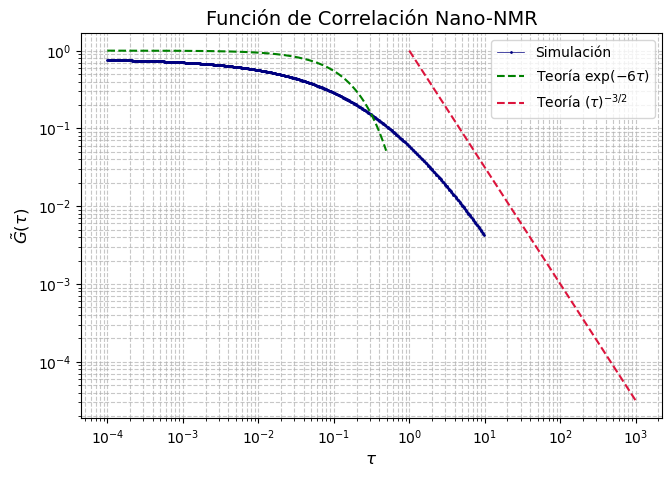

In [10]:
if __name__ == "__main__":
    # ejemplo (nm, µs)
    d = 1.0       # nm
    R = L = 15*d   # nm
    D = 1.0        # nm^2/µs (equiv a 1e-9 m^2/s)
    m_max = 200
    p_max = 200
    n_rho = 1500
    n_z = 1500

    print("Precomputando modos (Gauss)...")
    modes = precompute_modes_gauss(R, L, d, D, m_max, p_max, n_rho=n_rho, n_z=n_z)
    print("Hecho. Evaluando G(t) vectorizado...")
    times_us = np.logspace(-4, 5, 1000)  # µs
    tau_vals=times_us*D/d**2
    Gvals = G_bulk_vectorized(times_us, modes)
    np.savetxt("data/G_vs_t.dat", np.c_[times_us, tau_vals, Gvals], header="Tiempo(s) Tau G(t)", fmt="%.9e")

    # gráfica
    import matplotlib.pyplot as plt
    plt.figure(figsize=(7.5,5))
    plt.loglog(tau_vals[tau_vals<10], Gvals[tau_vals<10], "o-", label="Simulación", color="navy", markersize=1, linewidth=0.5)
    plt.plot(tau_vals[tau_vals<0.5], np.exp(-6*tau_vals[tau_vals<0.5]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
    plt.plot(tau_vals[(tau_vals>=1)&(tau_vals<=1000)], (tau_vals[(tau_vals>=1)&(tau_vals<=1000)])**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
    # plt.xlabel("Tiempo (s)", fontsize=12)
    plt.xlabel(r"$\tau$", fontsize=12)
    plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
    plt.title("Función de Correlación Nano-NMR", fontsize=14)
    plt.legend()
    plt.grid(which="both", ls='--', alpha=0.7)
    # plt.savefig("figuras/correlacion_nanoNMR.pdf", bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

# Time-dependent accumulation on the surface and Harmonic Measure

## Integrales de superficie: $B_\text{bottom}$, $B_\text{top}$ y $Z_\text{wall}$

En esta sección calculamos las integrales de superficie que aparecen en la contribución de las partículas **adsorbidas** al campo dipolar.

Recordemos que el acoplamiento dipolar entre un espín en la posición $(\rho, z)$ y el centro del NV (en el origen) está dado por

$$
W(\rho,z)
= \rho \left[
\frac{3 z^2}{(\rho^2 + z^2)^{5/2}}
- \frac{1}{(\rho^2 + z^2)^{3/2}}
\right],
$$

que corresponde esencialmente a
$$
W(\rho,z) \propto \rho\, \frac{Y_2^0(\theta)}{r^3},
\quad r = \sqrt{\rho^2 + z^2},
$$

con $Y_2^0$ el armónico esférico cuadrupolar que entra en el campo dipolar.

La idea es proyectar este peso $W(\rho,z)$ sobre las funciones propias radiales y axiales de la difusión confinada:

- En dirección radial, los modos vienen dados por las funciones de Bessel $J_0(\beta_p \rho)$, con
  $$
  \beta_p = \frac{\xi_p}{R},
  $$
  donde $\xi_p$ es el $p$-ésimo cero de $J_0$.

- En dirección axial, los modos vienen dados por senos y cosenos con números de onda
  $$
  \eta_m^{(e)} = \frac{2 m \pi}{L},
  \qquad
  \eta_m^{(o)} = \frac{(2m-1)\pi}{L},
  $$
  que ya se usaron en el propagador con condiciones de frontera de Dirichlet en $z=d$ y $z=d+L$.

Para los **fondos** (bottom) y **tapas** (top) del cilindro, definimos los coeficientes radiales

$$
B_\text{bottom}^{(p)} =
\int_0^R W(\rho, d)\, J_0(\beta_p \rho) \, d\rho,
$$

$$
B_\text{top}^{(p)} =
\int_0^R W(\rho, d+L)\, J_0(\beta_p \rho) \, d\rho.
$$

Estos coeficientes son las proyecciones del campo dipolar sobre los modos radiales en las superficies $z=d$ y $z=d+L$. Físicamente, capturan “qué tan fuerte” acopla cada modo radial $p$ con los espines adsorbidos en el fondo o en la tapa.

Para la **pared lateral** del cilindro (en $\rho = R$) proyectamos el peso dipolar a lo largo del eje $z$, sobre los modos axiales:

$$
Z_\text{sin}^{(m)} =
\int_d^{d+L} W(R, z)\,
\sin\!\big[\eta_m^{(e)} (z - d - L/2)\big] \, dz,
$$

$$
Z_\text{cos}^{(m)} =
\int_d^{d+L} W(R, z)\,
\cos\!\big[\eta_m^{(o)} (z - d - L/2)\big] \, dz.
$$

- $Z_\text{sin}^{(m)}$ es la proyección sobre los modos **pares** en $z$ (funciones seno).
- $Z_\text{cos}^{(m)}$ es la proyección sobre los modos **impares** en $z$ (funciones coseno).

En el código, estas integrales se calculan numéricamente mediante cuadratura de Gauss-Legendre en los intervalos:

- $\rho \in [0, R]$,
- $z \in [d, d+L]$,

haciendo el cambio de variable estándar de $[-1,1]$ a cada intervalo físico.

In [11]:
import numpy as np
from scipy import special
import math

# ---------- Integrales de superficie (solo W, sin modos todavía) ----------

def precompute_surface_integrals(R, L, d, modes, n_rho=80, n_z=80):
    """
    Calcula:
      - B_bottom[p] = ∫_0^R W(rho, d)      J0(beta_p rho) d rho
      - B_top[p]    = ∫_0^R W(rho, d+L)    J0(beta_p rho) d rho
      - Z_sin_wall[m] = ∫_d^{d+L} W(R, z) sin(eta_e (z - d - L/2)) dz
      - Z_cos_wall[m] = ∫_d^{d+L} W(R, z) cos(eta_o (z - d - L/2)) dz
    usando Gauss-Legendre.
    """
    betas = modes["betas"]     # shape (p_max,)
    m_max, p_max = modes["I_sin"].shape

    # Gauss en rho
    x_r, w_r = np.polynomial.legendre.leggauss(n_rho)
    rho_nodes = 0.5*(R - 0.0)*x_r + 0.5*(R + 0.0)
    rho_weights = 0.5*(R - 0.0)*w_r

    # Gauss en z
    x_z, w_z = np.polynomial.legendre.leggauss(n_z)
    z_nodes  = 0.5*((d+L) - d)*x_z + 0.5*((d+L) + d)
    z_weights = 0.5*((d+L) - d)*w_z

    W_bottom = W_rz_vec(rho_nodes, d)       # shape (n_rho,)
    W_top    = W_rz_vec(rho_nodes, d+L)     # shape (n_rho,)

    # W en la pared
    W_wall_z = W_rz_vec(np.full_like(z_nodes, R), z_nodes)  # shape (n_z,)

    # Precomputar J0(beta_p * rho) para todas las p
    J0_r = np.zeros((p_max, n_rho))
    for p in range(p_max):
        J0_r[p, :] = special.j0(betas[p] * rho_nodes)

    # B_bottom, B_top
    B_bottom = np.zeros(p_max)
    B_top    = np.zeros(p_max)
    for p in range(p_max):
        B_bottom[p] = np.sum(W_bottom * J0_r[p, :] * rho_weights)
        B_top[p]    = np.sum(W_top    * J0_r[p, :] * rho_weights)

    # Z_sin_wall, Z_cos_wall (solo dependen de m)
    Z_sin_wall = np.zeros(m_max)
    Z_cos_wall = np.zeros(m_max)
    for m in range(1, m_max+1):
        eta_e = 2.0 * m * math.pi / L
        eta_o = (2.0*m - 1.0) * math.pi / L
        phase = z_nodes - d - 0.5*L
        sin_ax = np.sin(eta_e * phase)
        cos_ax = np.cos(eta_o * phase)

        Z_sin_wall[m-1] = np.sum(W_wall_z * sin_ax * z_weights)
        Z_cos_wall[m-1] = np.sum(W_wall_z * cos_ax * z_weights)

    return {
        "B_bottom": B_bottom,
        "B_top": B_top,
        "Z_sin_wall": Z_sin_wall,
        "Z_cos_wall": Z_cos_wall,
    }


## Pesos modales de superficie $F_{m,p}$

Una vez que tenemos:

- Los modos de volumen (bulk), codificados en las integrales
  $I_\text{sin}^{(m,p)}$ e $I_\text{cos}^{(m,p)}$,
- y las proyecciones de superficie
  $B_\text{bottom}^{(p)}$, $B_\text{top}^{(p)}$,
  $Z_\text{sin}^{(m)}$, $Z_\text{cos}^{(m)}$,

podemos construir los **pesos modales de superficie** $F_{m,p}$, que miden cuánto contribuye cada modo $(m,p)$ a la acumulación de espines en la superficie y, por lo tanto, a la correlación de campo debida a la parte “sticky”.

Recordemos que los autovalores asociados a cada modo son

$$
\lambda_{m,p}^{(e)\,2} = \beta_p^2 + \eta_m^{(e)\,2},
\qquad
\lambda_{m,p}^{(o)\,2} = \beta_p^2 + \eta_m^{(o)\,2},
$$

donde

$$
\eta_m^{(e)} = \frac{2m\pi}{L},
\qquad
\eta_m^{(o)} = \frac{(2m-1)\pi}{L}.
$$

Los ceros de $J_0$ se denotan por
$$
\xi_p \quad\text{tal que}\quad J_0(\xi_p) = 0,
$$
y obedecen la condición de frontera radial de Dirichlet en $\rho = R$.
En esa frontera,
$$
\beta_p = \frac{\xi_p}{R},
\qquad
J_1(\xi_p) = \frac{d J_0}{d\xi}(\xi_p)
$$
aparece en las normalizaciones de los modos radiales.

En la parte de los **fondos y tapas** del cilindro, las derivadas normales de las funciones propias en $z$ generan factores axiales que denotamos

$$
C_\text{sin}^{(m,p)} =
\frac{(-1)^m\,2m\pi}{L\,\lambda_{m,p}^{(e)\,2}},
\qquad
C_\text{cos}^{(m,p)} =
\frac{(-1)^m\,(2m-1)\pi}{L\,\lambda_{m,p}^{(o)\,2}}.
$$

Estos provienen de:

- La derivada normal en $z$ (top/bottom caps),
- Más la división por $\lambda^2$ que aparece al integrar el propagador en el tiempo para construir la función de Green.

Con estos coeficientes, la contribución de los **caps** (fondos y tapas) al peso modal se escribe

$$
F_{m,p}^\text{caps}
=
\frac{B_\text{bottom}^{(p)} - B_\text{top}^{(p)}}{J_1(\xi_p)^2}
\left[
C_\text{sin}^{(m,p)}\, I_\text{sin}^{(m,p)}
+ C_\text{cos}^{(m,p)}\, I_\text{cos}^{(m,p)}
\right].
$$

Aquí,

- $I_\text{sin}^{(m,p)}$ e $I_\text{cos}^{(m,p)}$ son las integrales de volumen (bulk) que ya se calcularon al construir $G_\text{bulk}(t)$,
- $B_\text{bottom}^{(p)}$ y $B_\text{top}^{(p)}$ codifican el acoplamiento dipolar con los caps,
- El factor $1/J_1(\xi_p)^2$ viene de la normalización de los modos de Bessel en el volumen.

Para la **pared lateral** del cilindro, la derivada normal en $\rho$ produce un factor proporcional a $\beta_p / J_1(\xi_p)$ (usando las relaciones de recurrencia de Bessel y la condición de frontera de Dirichlet). Esta contribución se escribe

$$
F_{m,p}^\text{wall} =
\frac{\beta_p}{J_1(\xi_p)}
\left[
\frac{I_\text{sin}^{(m,p)}\, Z_\text{sin}^{(m)}}{\lambda_{m,p}^{(e)\,2}}
+
\frac{I_\text{cos}^{(m,p)}\, Z_\text{cos}^{(m)}}{\lambda_{m,p}^{(o)\,2}}
\right].
$$

Finalmente, el peso modal total asociado al modo $(m,p)$ es

$$
F_{m,p} =
F_{m,p}^\text{caps}
+
F_{m,p}^\text{wall}.
$$

Físicamente, $F_{m,p}$ recoge, en una sola cantidad:

- Cómo de fuerte está excitado el modo de difusión $(m,p)$ en el volumen,
- Cómo se proyecta este modo sobre las distintas partes de la superficie (fondos, tapa, pared),
- Y cómo se combina todo ello con el acoplamiento dipolar $W(\rho,z)$.

En el código, esto se implementa en 2 pasos:

1. Se calculan $F_{m,p}^\text{caps}$ a partir de `B_bottom`, `B_top`, `I_sin`, `I_cos` y los coeficientes axiales `C_sin`, `C_cos`.
2. Se calculan $F_{m,p}^\text{wall}$ a partir de `Z_sin_wall`, `Z_cos_wall`, `I_sin`, `I_cos` y la normalización radial.

Luego se suma todo en `F[mi, p] = F_caps + F_wall`.

In [12]:
# # ---------- Pesos modales F_{m,p} de superficie ----------

# def precompute_surface_modes(R, L, d, modes, surface_ints):
#     """
#     Construye F_{m,p} tal como en las fórmulas de arriba.
#     """
#     I_sin = modes["I_sin"]      # shape (m_max, p_max)
#     I_cos = modes["I_cos"]
#     betas = modes["betas"]
#     lambda2_e = modes["lambda2_e"]  # beta^2 + eta_e^2
#     lambda2_o = modes["lambda2_o"]  # beta^2 + eta_o^2

#     zeros = special.jn_zeros(0, I_sin.shape[1])
#     J1_at_zeros = special.j1(zeros)

#     B_bottom = surface_ints["B_bottom"]
#     B_top    = surface_ints["B_top"]
#     Z_sin_wall = surface_ints["Z_sin_wall"]
#     Z_cos_wall = surface_ints["Z_cos_wall"]

#     m_max, p_max = I_sin.shape
#     F = np.zeros((m_max, p_max))

#     for m in range(1, m_max+1):
#         mi = m - 1
#         eta_e = 2.0 * m * math.pi / L
#         eta_o = (2.0*m - 1.0) * math.pi / L

#         for p in range(p_max):
#             beta = betas[p]
#             lam2_e = lambda2_e[mi, p]
#             lam2_o = lambda2_o[mi, p]
#             J1 = J1_at_zeros[p]

#             Is = I_sin[mi, p]
#             Ic = I_cos[mi, p]

#             # Coeficientes axiales C_sin, C_cos
#             C_sin = ((-1)**m) * (2.0*m*math.pi) / (L * lam2_e)
#             C_cos = ((-1)**m) * ((2.0*m - 1.0)*math.pi) / (L * lam2_o)

#             B_delta = B_bottom[p] - B_top[p]

#             # Caps
#             F_caps = (B_delta / (J1*J1)) * (C_sin*Is + C_cos*Ic)

#             # Wall
#             Zs = Z_sin_wall[mi]
#             Zc = Z_cos_wall[mi]

#             F_wall = (beta / J1) * (Is * Zs / lam2_e + Ic * Zc / lam2_o)

#             F[mi, p] = F_caps + F_wall

#     return {
#         "F": F,             # F_{m,p}
#         "lambda2_o": modes["lambda2_o"],  # para usar en el factor temporal
#     }

def precompute_surface_modes(R, L, d, modes, surface_ints):
    """
    Construye F^{even}_{m,p} y F^{odd}_{m,p} tal como en la expresión analítica.
    """
    I_sin = modes["I_sin"]      # even
    I_cos = modes["I_cos"]      # odd
    betas = modes["betas"]
    lambda2_e = modes["lambda2_e"]
    lambda2_o = modes["lambda2_o"]

    zeros = special.jn_zeros(0, I_sin.shape[1])
    J1_at_zeros = special.j1(zeros)

    B_bottom = surface_ints["B_bottom"]
    B_top    = surface_ints["B_top"]
    Z_sin_wall = surface_ints["Z_sin_wall"]
    Z_cos_wall = surface_ints["Z_cos_wall"]

    m_max, p_max = I_sin.shape
    F_even = np.zeros((m_max, p_max))
    F_odd  = np.zeros((m_max, p_max))

    for m in range(1, m_max+1):
        mi = m - 1

        for p in range(p_max):
            beta = betas[p]
            lam2_e = lambda2_e[mi, p]
            lam2_o = lambda2_o[mi, p]
            J1 = J1_at_zeros[p]

            Is = I_sin[mi, p]   # even
            Ic = I_cos[mi, p]   # odd

            # Coeficientes axiales
            C_sin = ((-1)**m) * (2.0*m*math.pi) / (L * lam2_e)
            C_cos = ((-1)**m) * ((2.0*m - 1.0)*math.pi) / (L * lam2_o)

            B_delta = B_bottom[p] - B_top[p]

            # Caps
            F_caps_even = (B_delta / (J1*J1)) * (C_sin * Is)
            F_caps_odd  = (B_delta / (J1*J1)) * (C_cos * Ic)

            # Wall
            Zs = Z_sin_wall[mi]
            Zc = Z_cos_wall[mi]

            F_wall_even = (beta / J1) * (Is * Zs / lam2_e)
            F_wall_odd  = (beta / J1) * (Ic * Zc / lam2_o)

            F_even[mi, p] = F_caps_even + F_wall_even
            F_odd [mi, p] = F_caps_odd  + F_wall_odd

    return {
        "F_even": F_even,
        "F_odd":  F_odd,
        "lambda2_even": lambda2_e,
        "lambda2_odd":  lambda2_o,
    }

## Evolución temporal de la acumulación en superficie

Una vez calculados los pesos modales de superficie $F_{m,p}$, la contribución de la superficie a la función de correlación se puede escribir como una suma de modos decaimiento-exponencial.

La estructura general es

$$
G_\text{surface}(t)
=
\frac{8\pi^2}{V}
\sum_{m,p}
F_{m,p}\,
\left[
1 - e^{-D\,\lambda_{m,p}^2\, t}
\right],
$$

donde:

- $V = \pi R^2 L$ es el volumen del cilindro,
- $D$ es la constante de difusión,
- $\lambda_{m,p}^2$ son los autovalores del operador Laplaciano con condiciones de Dirichlet (las mismas que en el propagador),
- El factor $1 - e^{-D\lambda_{m,p}^2 t}$ aparece al integrar en el tiempo el propagador:
  $$\int_0^t e^{-D\lambda_{m,p}^2 t'} dt' = \frac{1 - e^{-D\lambda_{m,p}^2 t}}{D\lambda_{m,p}^2}.$$

En la práctica:

- En los pesos $F_{m,p}$ ya están incorporados los factores $1/\lambda_{m,p}^2$ que vienen de la integración temporal y de la construcción de la Green function,
- Por eso, en la suma numérica aparece sólo el factor $\left[1 - e^{-D\lambda_{m,p}^2 t}\right]$.

En el código, la función `sum_surface_modes_numeric` implementa la suma

$$
S(t) = \sum_{m,p} F_{m,p}
\left[1 - e^{-D\,\lambda_{m,p}^2\, t}\right],
$$

y devuelve $S(t)$ para todos los tiempos de interés. El prefactor global $8\pi^2 / V$ (con el signo que se escoja según la convención del manuscrito) se aplica después en la función de alto nivel `G_surface_vectorized`.

In [13]:
# ---------- G_surface(t) y G_surface(∞) ----------

from numba import njit, prange

@njit(parallel=True, fastmath=True)
# def sum_surface_modes_numeric(F, lambda2_o, D, times):
    # m_max, p_max = F.shape
    # n_times = times.shape[0]
    # G = np.zeros(n_times, dtype=np.float64)
    # for ti in prange(n_times):
    #     t = times[ti]
    #     acc = 0.0
    #     for mi in range(m_max):
    #         for pi in range(p_max):
    #             lam2 = lambda2_o[mi, pi]
    #             coeff = F[mi, pi]
    #             acc += coeff * (1.0 - math.exp(- D*lam2*t))
    #     G[ti] = acc
    # return G
def sum_surface_modes_numeric(F_even, lambda2_even, F_odd, lambda2_odd, D, times):
    m_max, p_max = F_even.shape
    n_times = times.shape[0]
    G = np.zeros(n_times, dtype=np.float64)
    for ti in prange(n_times):
        t = times[ti]
        acc = 0.0
        for mi in range(m_max):
            for pi in range(p_max):
                x_e = D * lambda2_even[mi, pi] * t
                x_o = D * lambda2_odd[mi, pi] * t
                # numéricamente estable: 1 - exp(-x) = -expm1(-x) (evita cancelación para x<<1)
                # math.expm1 puede no estar disponible en todas las versiones de numba; si no, usar 1-math.exp(-x)
                acc += F_even[mi, pi] * (-math.expm1(-x_e))
                acc += F_odd[mi, pi]  * (-math.expm1(-x_o))
        G[ti] = acc
    return G
    

## $G_{\text{surface}}(t)$ y límite $t \to \infty$ (medida armónica)

La contribución de la superficie a la función de correlación puede escribirse como una suma de modos que crecen monótonamente desde $0$ hasta un valor de saturación cuando pasa el tiempo de difusión característico.

Esquemáticamente:
$$
G_{\text{surface}}(t)
=
\frac{8\pi^2}{V}
\sum_{m,p} F_{m,p}
\left[
1 - e^{-D\,\lambda_{m,p}^2\, t}
\right],
$$

donde:

- $V = \pi R^2 L$ es el volumen del cilindro,
- $D$ es el coeficiente de difusión,
- $\lambda_{m,p}^2$ son los autovalores del operador de difusión con fronteras de Dirichlet,
- $F_{m,p}$ son los pesos modales de superficie que ya codifican:
  - la excitación de cada modo $(m,p)$ en el bulk,
  - su proyección sobre la superficie (fondos, tapa, pared),
  - y el acoplamiento dipolar $W(\rho,z)$,
  - incluyendo los factores $1/\lambda_{m,p}^2$ que salen de integrar el propagador en el tiempo.

La estructura temporal típica viene de:
$$
\int_0^t e^{-D\lambda_{m,p}^2 t'} \, dt' =
\frac{1 - e^{-D\lambda_{m,p}^2 t}}{D\lambda_{m,p}^2},
$$

y por eso aparecen términos del tipo $1 - e^{-D\lambda_{m,p}^2 t}$. Como los factores $1/\lambda_{m,p}^2$ ya se absorbieron en la definición de $F_{m,p}$, en la implementación numérica solo se conserva explícitamente el factor:
$$
\left[1 - e^{-D\lambda_{m,p}^2 t}\right].
$$

En el código:

- `sum_surface_modes_numeric(F, lambda2_o, D, times)` calcula
  $$ 
  S(t) = \sum_{m,p} F_{m,p}
  \left[1 - e^{-D\,\lambda_{m,p}^2\, t}\right],
  $$
- `G_surface_vectorized(times_us, modes, surf_modes)` aplica luego el prefactor geométrico
  $$
  G_{\text{surface}}(t)
  =
  \frac{8\pi^2}{V}\, S(t),
  $$
  con un signo global consistente con la convención elegida para $W(\rho,z)$ y para el campo dipolar.

En el límite de tiempos largos, $t \gg \tau_v \sim d^2/D$, las exponenciales se anulan y se obtiene:
$$
G_{\text{surface}}(t \to \infty)
=
\frac{8\pi^2}{V}
\sum_{m,p} F_{m,p}.
$$

Esta cantidad es la contribución de la **medida armónica** a la correlación: corresponde a dejar difundir a todas las partículas hasta que se adsorben en la superficie, de modo que toda la probabilidad queda en la frontera, distribuida según la medida armónica del problema de difusión con condiciones de Dirichlet.

En el código, la función `G_surface_infty_from_modes(modes, surf_modes)` implementa directamente:
$$
G_{\text{surface}}^{(\infty)} =
\frac{8\pi^2}{V}
\sum_{m,p} F_{m,p},
$$
sin integrar explícitamente en el tiempo, usando solo los pesos modales $F_{m,p}$.

Comparar este valor con `G_surface(t_max)` para tiempos muy grandes sirve como chequeo de consistencia numérica:
$$
\frac{G_{\text{surface}}(t_{\max})}{G_{\text{surface}}^{(\infty)}} \approx 1,
$$
si $m_{\max}$, $p_{\max}$ y las cuadraturas en $\rho$ y $z$ son suficientemente grandes.

In [14]:
def G_surface_vectorized(times_us, modes, surf_modes):
    times_us = np.asarray(times_us, dtype=np.float64)
    # F = surf_modes["F"]
    # lambda2_o = surf_modes["lambda2_o"]
    F_e = surf_modes["F_even"]
    lam2_e = surf_modes["lambda2_even"]
    F_o = surf_modes["F_odd"]
    lam2_o = surf_modes["lambda2_odd"]
    D = modes["D"]
    R = modes["R"]
    L = modes["L"]
    V = math.pi * R*R * L

    # Prefactor -8π^2 / V según tu ecuación de G^{surface}(t)
    # prefactor = -8.0 * math.pi**2 / V
    # return prefactor * sums
    sums = sum_surface_modes_numeric(F_e, lam2_e, F_o, lam2_o, D, times_us)
    prefactor = -8.0 * math.pi**2 / V
    return prefactor * sums

# def G_surface_infty_from_modes(modes, surf_modes):
#     """
#     Medida armónica de superficie obtenida de F_{m,p}:
#       G_∞ = (8π^2 / V) * sum_{m,p} F_{m,p}
#     """
#     F = surf_modes["F"]
#     R = modes["R"]
#     L = modes["L"]
#     V = math.pi * R*R * L
#     return -8.0 * math.pi**2 * np.sum(F) / V

def G_surface_infty_from_modes(modes, surf_modes):
    """
    Medida armónica de superficie (límite t → ∞):

      G_∞ = - (8π^2 / V) * sum_{m,p} [ F^{even}_{m,p} + F^{odd}_{m,p} ]
    """
    F_even = surf_modes["F_even"]
    F_odd  = surf_modes["F_odd"]

    R = modes["R"]
    L = modes["L"]
    V = math.pi * R * R * L

    return -8.0 * math.pi**2 * (np.sum(F_even) + np.sum(F_odd)) / V

## Resumen del pipeline numérico y parámetros físicos

El bloque principal del script coordina todo el cálculo de la correlación, separando claramente las contribuciones de bulk y de superficie.

1. **Parámetros geométricos y físicos**

   - $d$: posición del fondo del cilindro respecto al origen (en nm),
   - $R$: radio del cilindro (en nm),
   - $L$: altura del cilindro (en nm),
   - $D$: coeficiente de difusión (en nm$^2$/µs).

   En este ejemplo se usa $R = L = 5d$, lo que define la geometría del cilindro alrededor del NV.

2. **Truncaciones modales**

   - $m_{\max}$: número de modos axiales considerados,
   - $p_{\max}$: número de modos radiales (ceros de $J_0$) incluidos.

   Estas truncaciones controlan la precisión de la expansión espectral tanto del propagador como de las funciones de correlación.

3. **Cuadraturas de Gauss-Legendre**

   - $n_{\rho,\text{bulk}}$ y $n_{z,\text{bulk}}$ fijan el número de nodos de cuadratura para las integrales de volumen que entran en $G_{\text{bulk}}(t)$.
   - $n_{\rho,\text{surf}}$ y $n_{z,\text{surf}}$ fijan el número de nodos de cuadratura para las integrales de superficie que entran en $G_{\text{surface}}(t)$.

   A mayor número de nodos, mayor precisión (y mayor coste computacional).

4. **Pre-cálculo de modos de bulk**

   La llamada a `precompute_modes_gauss(R, L, d, D, m_max, p_max, ...)` devuelve:

   - las integrales modales $I_{\sin}^{(m,p)}$ e $I_{\cos}^{(m,p)}$ que vienen de proyectar el acoplamiento dipolar $W(\rho,z)$ sobre las autofunciones del problema de difusión en el bulk,
   - los autovalores $\lambda_{m,p}^{(e)\,2}$ y $\lambda_{m,p}^{(o)\,2}$,
   - los parámetros auxiliares como los $\beta_p$ y la geometría $(R,L,d)$.

   Esta información encapsula la solución del problema de difusión con condiciones de Dirichlet en el volumen.

5. **Pre-cálculo de integrales de superficie**

   La función `precompute_surface_integrals(R, L, d, modes, ...)` calcula las proyecciones del acoplamiento dipolar $W(\rho,z)$ sobre los modos radiales y axiales, pero restringido a la superficie del cilindro:

   - $B_{\text{bottom}}^{(p)}$, $B_{\text{top}}^{(p)}$: integrales en las tapas (fondo y techo),
   - $Z_{\sin,\text{wall}}^{(m)}$, $Z_{\cos,\text{wall}}^{(m)}$: integrales a lo largo de la pared lateral $\rho = R$.

6. **Construcción de los pesos modales de superficie $F_{m,p}$**

   La función `precompute_surface_modes(R, L, d, modes, surface_ints)` combina:

   - los modos de bulk ($I_{\sin}^{(m,p)}$, $I_{\cos}^{(m,p)}$, $\lambda_{m,p}^2$),
   - las proyecciones en superficie ($B_{\text{bottom}}^{(p)}$, $B_{\text{top}}^{(p)}$, $Z_{\sin,\text{wall}}^{(m)}$, $Z_{\cos,\text{wall}}^{(m)}$),
   - las normalizaciones de Bessel $J_1(\xi_p)$,

   para producir los pesos $F_{m,p}$ que determinan la contribución de cada modo a la acumulación de espines en la superficie.

7. **Escala temporal adimensional**

   Se define el tiempo adimensional:
   $$
   \tau = \frac{D t}{d^2},
   $$
   y se generan tiempos `times_us` en escala logarítmica. Esto permite explorar de forma uniforme varios órdenes de magnitud en el tiempo de difusión.

8. **Cálculo de las correlaciones**

   - `G_bulk = G_bulk_vectorized(times_us, modes)` calcula la contribución de las partículas que permanecen en el bulk:
     $$
     G_{\text{bulk}}(t) = \frac{8\pi^2}{V}
     \sum_{m,p}
     \frac{I_{\sin}^{(m,p)\,2} e^{-D\lambda_{m,p}^{(e)\,2} t}
          + I_{\cos}^{(m,p)\,2} e^{-D\lambda_{m,p}^{(o)\,2} t}}
          {J_1(\xi_p)^2}.
     $$
   - `G_surface = G_surface_vectorized(times_us, modes, surf_modes)` calcula la contribución de las partículas adsorbidas en la superficie:
     $$
     G_{\text{surface}}(t) =
     \frac{8\pi^2}{V}
     \sum_{m,p} F_{m,p}
     \left[1 - e^{-D\lambda_{m,p}^2 t}\right].
     $$
   - `G_total = G_bulk + G_surface` es la correlación total predicha por el modelo sticky confinado en el cilindro.

9. **Chequeo del límite $t \to \infty$ (medida armónica)**

   Se evalúa la medida armónica directamente a partir de los pesos modales con la función `G_surface_infty_from_modes(modes, surf_modes)`, que implementa:
   $$
   G_{\text{surface}}^{(\infty)} =
   \frac{8\pi^2}{V}
   \sum_{m,p} F_{m,p}.
   $$

   Luego se compara con el valor numérico a tiempos muy largos:
   $$
   \frac{G_{\text{surface}}(t_{\max})}{G_{\text{surface}}^{(\infty)}} \approx 1,
   $$
   lo que sirve como diagnóstico de convergencia y de consistencia entre la dinámica dependiente de $t$ y el límite estacionario (medida armónica).

10. **Gráficas**

    Finalmente se representan en escala log-log:

    - $G_{\text{bulk}}(\tau)$,
    - $G_{\text{surface}}(\tau)$,
    - $G_{\text{total}}(\tau)$,

    lo que permite visualizar:

    - el régimen de decaimiento controlado por difusión en el bulk,
    - el relleno progresivo de la superficie (modelo sticky),
    - y el valor asintótico dominado por la distribución armónica de espines en la frontera del cilindro.


Precomputando modos de bulk (Gauss)...
Precomputando integrales de superficie...
Precomputando pesos modales de superficie...
Calculando G_bulk(t)...
Calculando G_surface(t)...

--- Diagnóstico superficie ---
G_surface_infty_from_modes  =  0.017668942159077737
G_surface(t_max) (numérico) =  0.017668942159077716
Relación G_surface(t_max) / G_surface_infty_from_modes =  0.9999999999999988


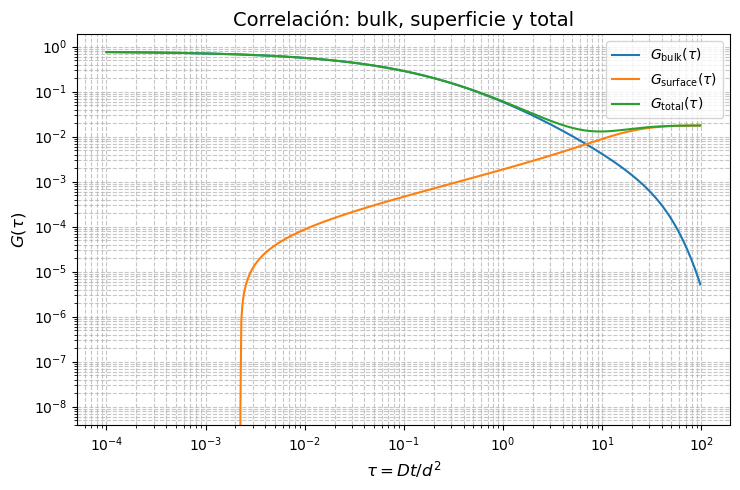

In [15]:
if __name__ == "__main__":
    # ------------------ Parámetros físicos y numéricos ------------------
    d = 1.0          # nm (offset desde el origen al fondo del cilindro)
    R = L = 5.0*d    # nm
    D = 1.0          # nm^2 / µs

    print("Precomputando modos de bulk (Gauss)...")
    

    print("Precomputando integrales de superficie...")
    surface_ints = precompute_surface_integrals(
        R, L, d,
        modes,
        n_rho=n_rho,
        n_z=n_z
    )

    print("Precomputando pesos modales de superficie...")
    surf_modes = precompute_surface_modes(R, L, d, modes, surface_ints)

    # ------------------ Tiempos y variable adimensional tau ------------------
    # times_us = np.logspace(-5, 4, 1000)  # µs
    # tau_vals = times_us * D / d**2      # τ = D t / d^2

    # ------------------ G_bulk(t) ------------------
    print("Calculando G_bulk(t)...")
    G_bulk = Gvals # G_bulk_vectorized(times_us, modes)

    # ------------------ G_surface(t) ------------------
    print("Calculando G_surface(t)...")
    G_surface = G_surface_vectorized(times_us, modes, surf_modes)

    # Suma total
    G_total = G_bulk + G_surface

    # ------------------ Límite t → ∞ de superficie (medida harmónica) ------------------
    G_surf_inf = G_surface_infty_from_modes(modes, surf_modes)

    print("\n--- Diagnóstico superficie ---")
    print("G_surface_infty_from_modes  = ", G_surf_inf)
    print("G_surface(t_max) (numérico) = ", G_surface[-1])
    print("Relación G_surface(t_max) / G_surface_infty_from_modes = ",
          G_surface[-1] / G_surf_inf if G_surf_inf != 0 else np.nan)

    # ------------------ Gráficas ------------------
    plt.figure(figsize=(7.5, 5))
    plt.loglog(tau_vals[tau_vals<100], G_bulk[tau_vals<100], label=r"$G_{\rm bulk}(\tau)$")
    plt.loglog(tau_vals[tau_vals<100], G_surface[tau_vals<100], label=r"$G_{\rm surface}(\tau)$")
    plt.loglog(tau_vals[tau_vals<100], G_total[tau_vals<100], label=r"$G_{\rm total}(\tau)$")
    
    plt.xlabel(r"$\tau = Dt/d^2$", fontsize=12)
    plt.ylabel(r"$G(\tau)$", fontsize=12)
    plt.title("Correlación: bulk, superficie y total", fontsize=14)
    plt.grid(which="both", ls="--", alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.show()